### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [2]:
monety_szare = cv2.imread('Monety_szare.bmp')
monety_szum = cv2.imread('Monety_szare_szum.bmp')

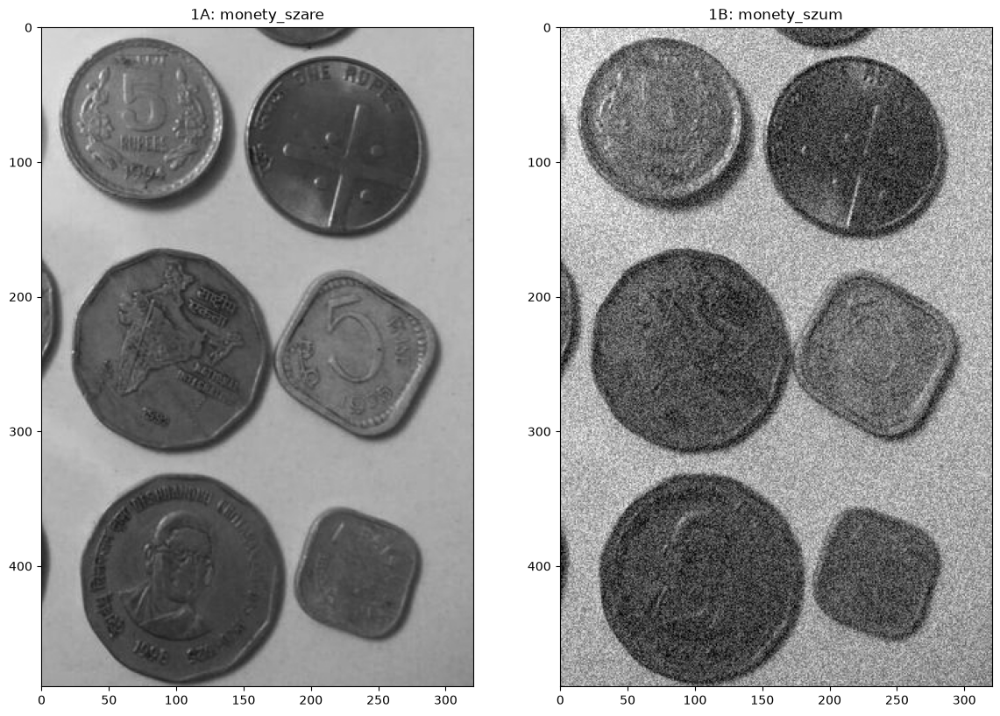

In [3]:
_, (a, b) = plt.subplots(1,2, figsize=(14,10))
a.imshow(monety_szare); a.title.set_text('1A: monety_szare')
b.imshow(monety_szum); b.title.set_text('1B: monety_szum')

In [4]:
def calc_histogram(image):
    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
    return hist

def show_histogram(image, T=None, axis=None, title='Histogram', color='black'):
    if axis is None:
        axis = plt.gca()
    axis.bar(np.arange(256), calc_histogram(image), width=1.0, color=color)
    if T is not None:
        axis.axvline(T, color='red', label=f'T = {T:.0f}')
        axis.legend()
    axis.set_title(title)
    axis.set_xlim(-10, 260)

def binarize_image(image, T, dark_objects=True):
    _, binary_image = cv2.threshold(image, T, 255, cv2.THRESH_BINARY_INV if dark_objects else cv2.THRESH_BINARY)
    return binary_image

def otsu_method(image):
    hist = calc_histogram(image)
    P = hist / hist.sum()
    i = np.arange(256)
    mu_T = (P * i).sum()
    sigma_T_squared = (P * ((i - mu_T) ** 2)).sum()
    best_t, best_sw = 0, np.inf
    for t in range(255):
        q1 = P[:t + 1].sum()
        q2 = P[t + 1:].sum()
        if q1 <= 0 or q2 <= 0:
            continue
        mu1 = (P[:t + 1] * i[:t + 1]).sum() / q1
        mu2 = (P[t + 1:] * i[t + 1:]).sum() / q2
        sigma1_squared = (P[:t + 1] * ((i[:t + 1] - mu1) ** 2)).sum() / q1
        sigma2_squared = (P[t + 1:] * ((i[t + 1:] - mu2) ** 2)).sum() / q2
        sw = q1 * sigma1_squared + q2 * sigma2_squared
        if sw < best_sw:
            best_sw = sw
            best_t = t
    sigma_b_squared = sigma_T_squared - best_sw
    eta = sigma_b_squared / sigma_T_squared if sigma_T_squared > 0 else 0.0
    return best_t, eta

def denoise_image(image, method, k=3):
    if method == 'mean':
        return cv2.blur(image, (k, k))
    elif method == 'median':
        return cv2.medianBlur(image, k)
    elif method == 'gaussian':
        return cv2.GaussianBlur(image, (k, k), 0)
    else:
        return image

def iou(a, b):
    a, b = a>0, b>0
    return (a & b).sum() / max((a | b).sum(), 1)

def show_images(images, titles, columns=3, size=4):
    rows = int(np.ceil(len(images) / columns))
    fig, axis = plt.subplots(rows, columns, figsize=(size * columns, size * rows))
    axis = np.atleast_1d(axis).ravel()
    for ax_, im, t in zip(axis, images, titles):
        ax_.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax_.set_title(t, fontsize=10)
        ax_.axis('off')
    for ax_ in axis[len(images):]:
        ax_.axis('off')
    plt.tight_layout()
    plt.show()

Rozwiązanie części 1A:

In [6]:
print('identical channels?', np.array_equal(monety_szare[..., 0], monety_szare[..., 1]))
print('identical channels szum?', np.array_equal(monety_szum[..., 0], monety_szum[..., 1]))

gray_image = cv2.cvtColor(monety_szare, cv2.COLOR_BGR2GRAY)
gray_noise = cv2.cvtColor(monety_szum, cv2.COLOR_BGR2GRAY)

print('\nmonety szare:')
print('shape:', gray_image.shape, '| type:', gray_image.dtype, '| min/max:', gray_image.min(), gray_image.max())

print('\nmonety szum:')
print('shape:', gray_noise.shape, '| type:', gray_noise.dtype, '| min/max:', gray_noise.min(), gray_noise.max())

identical channels? True
identical channels szum? True

monety szare:
shape: (490, 321) | type: uint8 | min/max: 19 254

monety szum:
shape: (490, 321) | type: uint8 | min/max: 0 255


Otsu method: T = 127, eta = 0.86


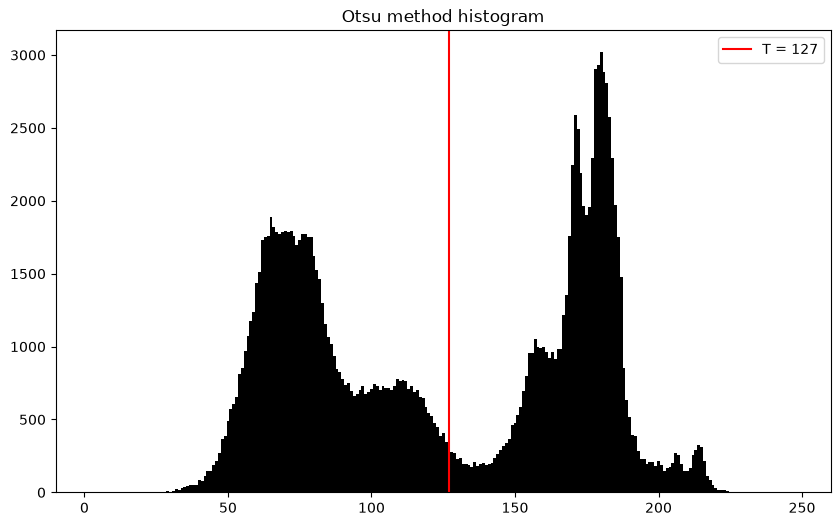

In [9]:
T_cv, _ = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
T_otsu, eta = otsu_method(gray_image)
print(f'Otsu method: T = {T_otsu:.0f}, eta = {eta:.2f}')

fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))
show_histogram(gray_image, T_otsu, axis=ax1, title='Otsu method histogram')
plt.show()

In [14]:
def threshold_exp(T=127):
    binary_image = binarize_image(gray_image, T)
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 4))
    a.imshow(gray_image, cmap='gray', vmin=0, vmax=255); a.set_title('oryginał'); a.axis('off')
    show_histogram(gray_image, T, b)
    c.imshow(binary_image, cmap='gray', vmin=0, vmax=255); c.axis('off')
    c.set_title(f'T={T}')
    plt.show()

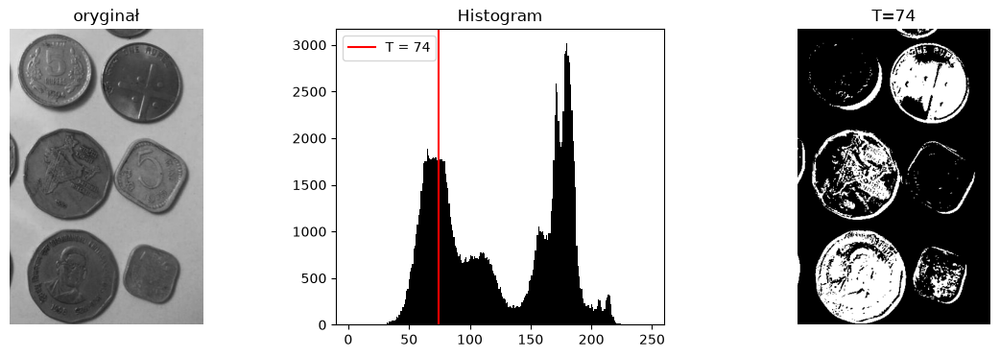

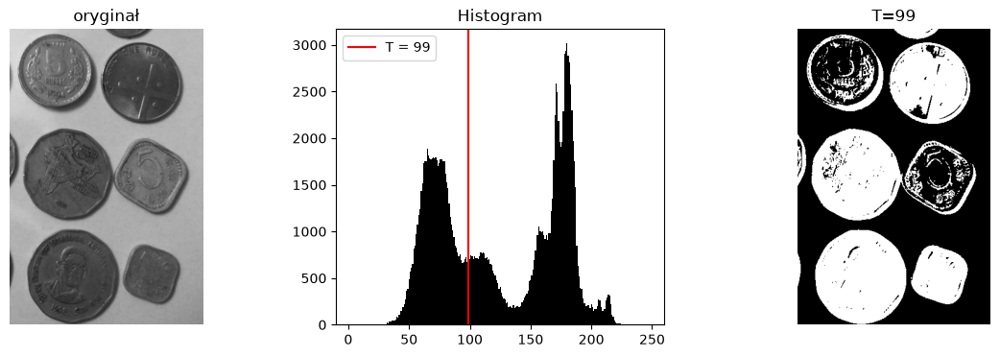

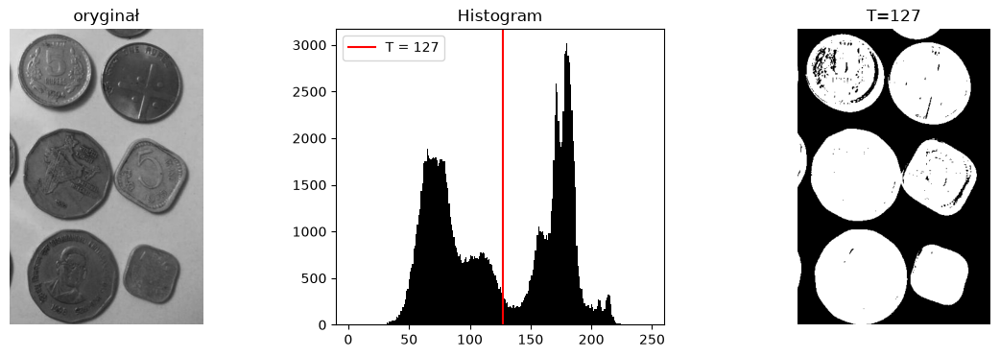

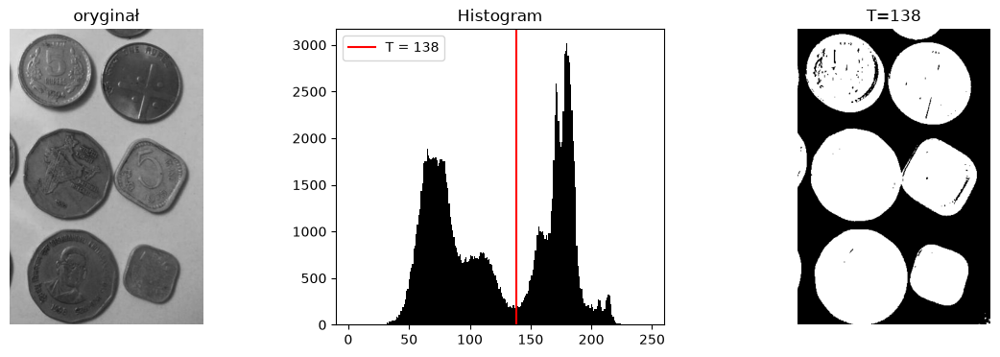

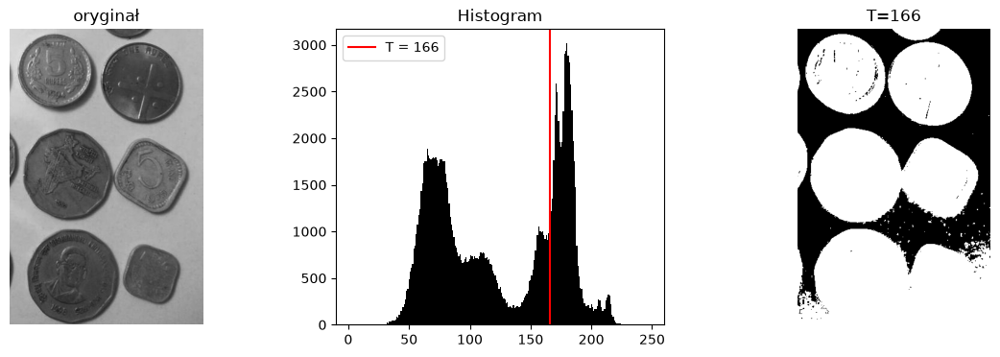

In [18]:
threshold_exp(T=74)
threshold_exp(T=99)
threshold_exp(T=T_otsu)
threshold_exp(T=138)
threshold_exp(T=166)

Rozwiązanie części 1B:


czysty      std=49.9 | % pikseli =0: 0.00 | % pikseli =255: 0.00
zaszumiony  std=56.3 | % pikseli =0: 0.13 | % pikseli =255: 0.16


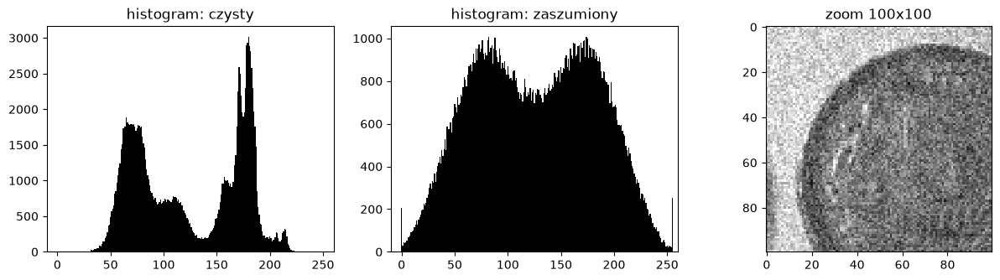

In [19]:
for name, im in [('czysty', gray_image), ('zaszumiony', gray_noise)]:
    print(f'{name:11s} std={im.std():.1f} | % pikseli =0: {(im == 0).mean() * 100:.2f} | % pikseli =255: {(im == 255).mean() * 100:.2f}')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
show_histogram(gray_image, axis=ax[0], title='histogram: czysty')
show_histogram(gray_noise, axis=ax[1], title='histogram: zaszumiony')
ax[2].imshow(gray_noise[:100, :100], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
ax[2].set_title('zoom 100x100'); plt.show()

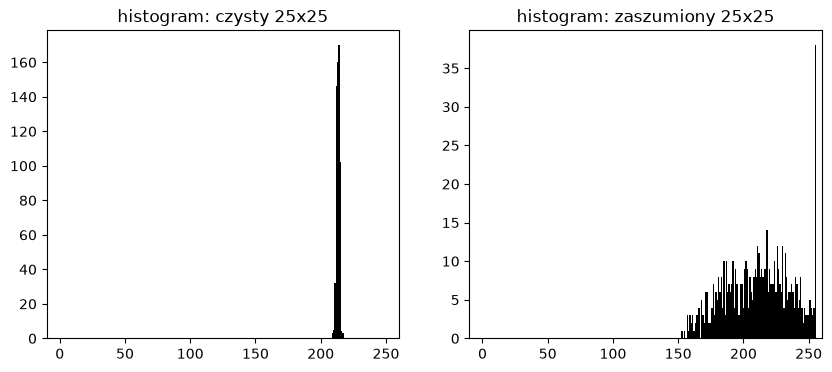

In [81]:
gray_iamge_part = gray_image[:25, :25]
gray_noise_part = gray_noise[:25, :25]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
show_histogram(gray_iamge_part, axis=ax[0], title='histogram: czysty 25x25')
show_histogram(gray_noise_part, axis=ax[1], title='histogram: zaszumiony 25x25')
plt.show()

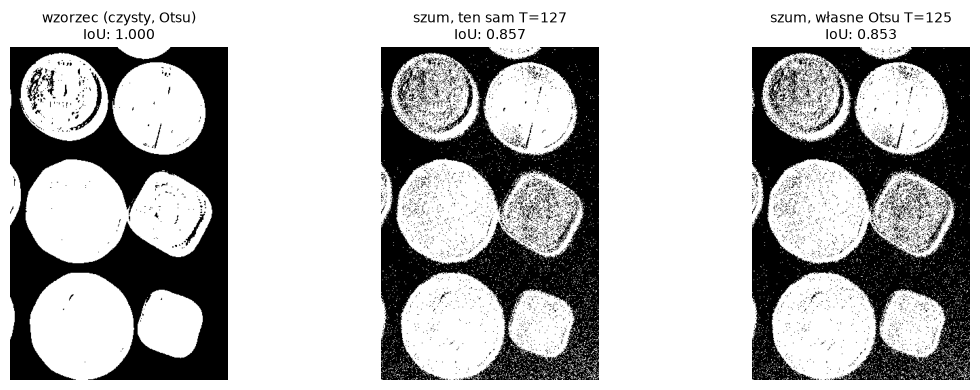

In [20]:
assert gray_image.shape == gray_noise.shape, 'obrazy mają różne rozmiary, IoU nie ma sensu'
ref = binarize_image(gray_image, T_cv)
T_szum, _ = cv2.threshold(gray_noise, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
warianty = {
    'wzorzec (czysty, Otsu)': ref,
    f'szum, ten sam T={T_cv:.0f}': binarize_image(gray_noise, T_cv),
    f'szum, własne Otsu T={T_szum:.0f}': binarize_image(gray_noise, T_szum),
}
show_images(list(warianty.values()),
      [f'{n}\nIoU: {iou(bw, ref):.3f}' for n, bw in warianty.items()])

metoda     k  T(Otsu)    IoU
mean       1      125  0.853
mean       3      127  0.963
mean       5      128  0.967
mean       7      128  0.964
mean       9      128  0.959
mean      11      128  0.953
mean      15      129  0.938
gaussian   1      125  0.853
gaussian   3      127  0.960
gaussian   5      127  0.968
gaussian   7      128  0.970
gaussian   9      128  0.969
gaussian  11      128  0.967
gaussian  15      128  0.963
median     1      125  0.853
median     3      127  0.952
median     5      128  0.965
median     7      128  0.966
median     9      128  0.965
median    11      128  0.962
median    15      129  0.951


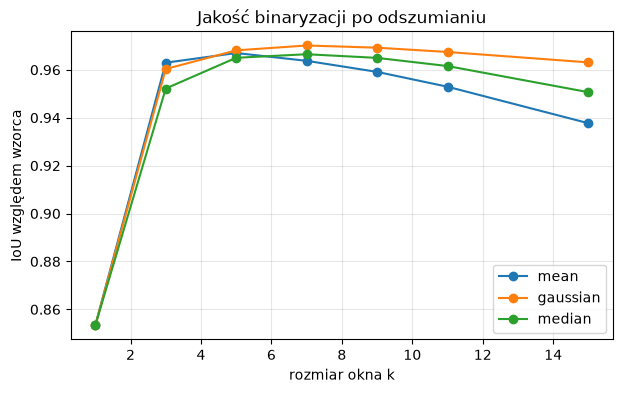

In [22]:
ks = [1, 3, 5, 7, 9, 11, 15]
method = ['mean', 'gaussian', 'median']
results = {m: [] for m in method}
print(f"{'metoda':8s} {'k':>3s} {'T(Otsu)':>8s} {'IoU':>6s}")
for m in method:
    for k in ks:
        f = denoise_image(gray_noise, m, k)
        T, _ = cv2.threshold(f, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        bi = binarize_image(f, T)
        results[m].append(iou(bi, ref))
        print(f'{m:8s} {k:3d} {T:8.0f} {results[m][-1]:6.3f}')
plt.figure(figsize=(7, 4))
for m in method:
    plt.plot(ks, results[m], marker='o', label=m)
plt.xlabel('rozmiar okna k'); plt.ylabel('IoU względem wzorca'); plt.legend(); plt.grid(alpha=.3)
plt.title('Jakość binaryzacji po odszumianiu'); plt.show()

In [23]:
def denoise_preview(method='mean', k=3, T=127, use_otsu=True):
    f = denoise_image(gray_noise, method, k)
    if use_otsu:
        T, _ = cv2.threshold(f, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = binarize_image(f, T)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(f, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'{method}, k={k}'); ax[0].axis('off')
    show_histogram(f, T, ax[1], 'histogram po odszumieniu')
    ax[2].imshow(bw, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'T={T:.0f} | IoU={iou(bw, ref):.3f}')
    plt.show()

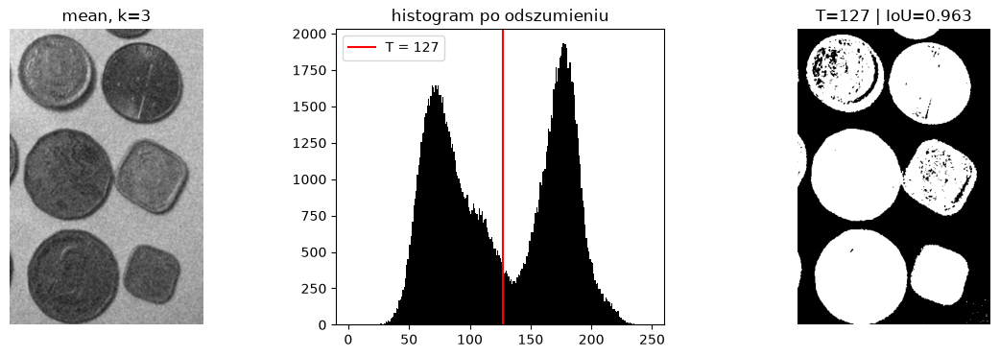

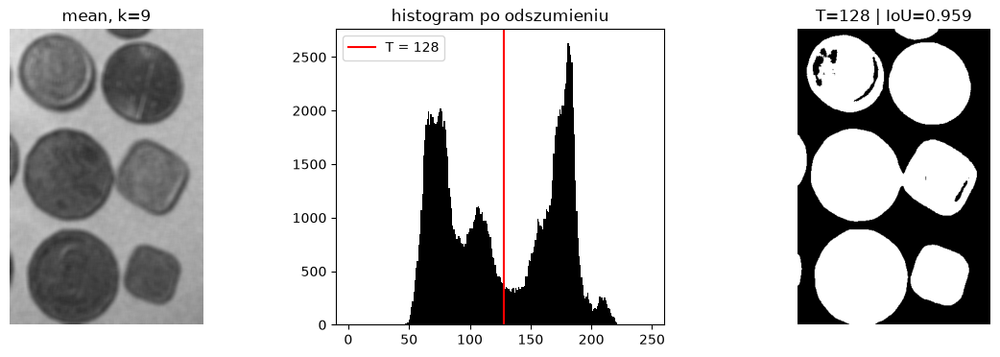

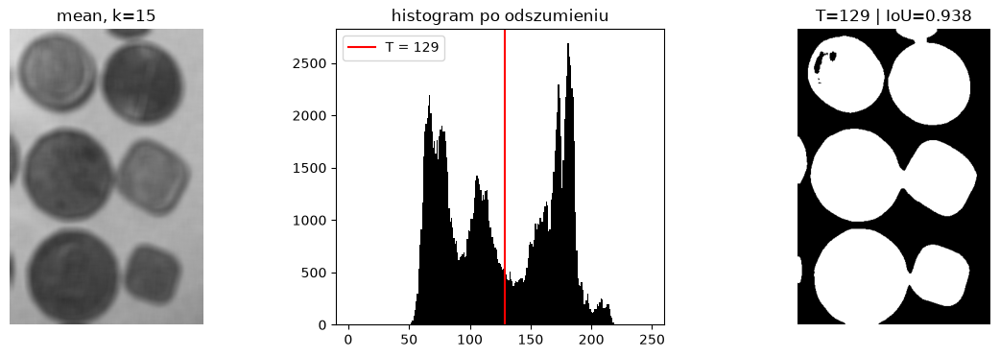

In [25]:
denoise_preview(method='mean', k=3)
denoise_preview(method='mean', k=9)
denoise_preview(method='mean', k=15)


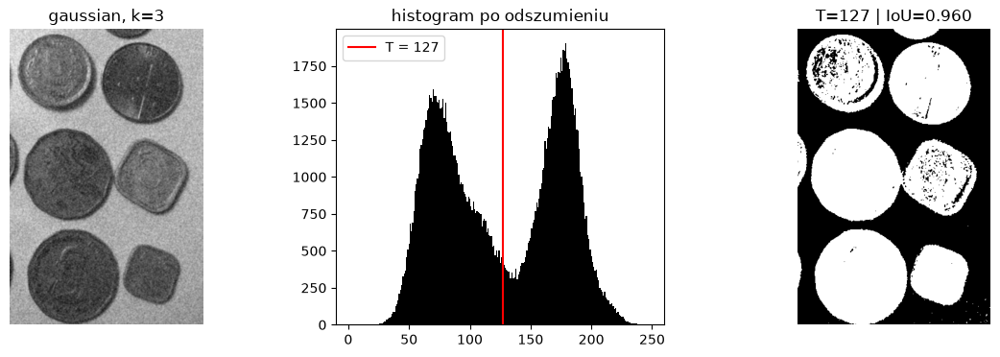

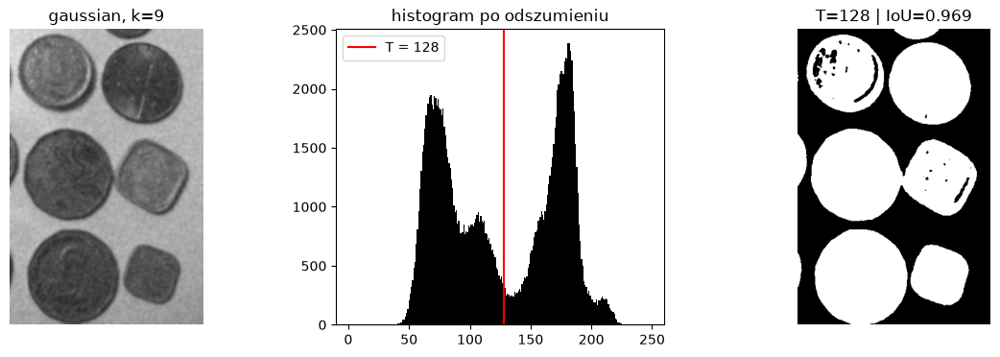

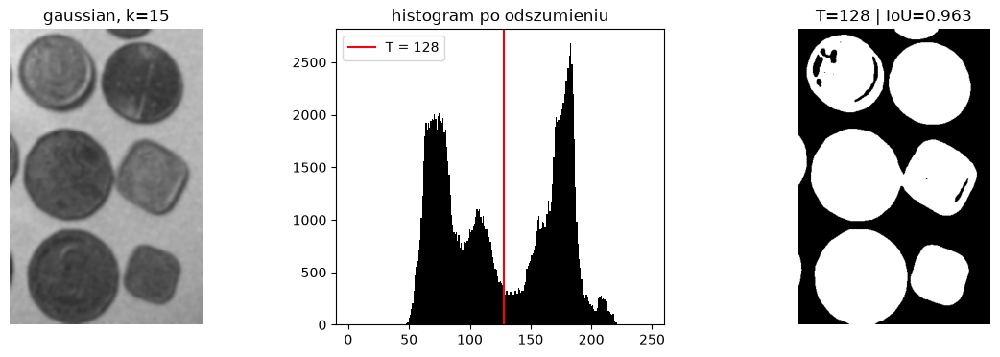

In [26]:
denoise_preview(method='gaussian', k=3)
denoise_preview(method='gaussian', k=9)
denoise_preview(method='gaussian', k=15)

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

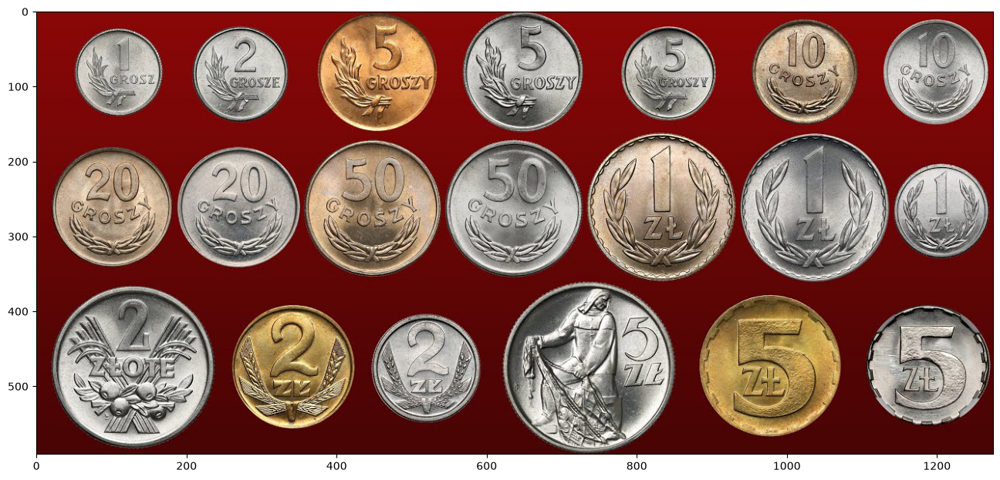

In [28]:
monety_kolor = cv2.imread('Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1]);

H: min/max = 0 179 | S: min/max = 0 255 | V: min/max = 0 255


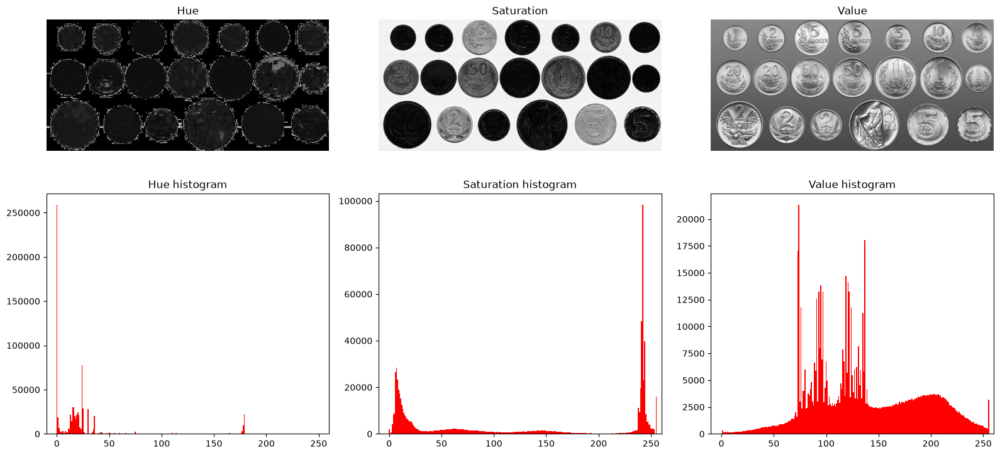

In [29]:
hsv_image = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv_image)
print('H: min/max =', H.min(), H.max(), '| S: min/max =', S.min(), S.max(), '| V: min/max =', V.min(), V.max())

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, channel) in enumerate([('Hue', H), ('Saturation', S), ('Value', V)]):
    ax[0, i].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[0, i].set_title(name); ax[0, i].axis('off')
    show_histogram(channel, axis=ax[1, i], title=f'{name} histogram', color='red')
# ax[1, 0].axis('off')
ax[0, 0].axis('off'); plt.tight_layout(); plt.show()

kanał   T(Otsu)    eta
H            92   0.87
S           131   0.90
V           148   0.73
B            88   0.82
G            90   0.85
R           148   0.73
gray        108   0.84


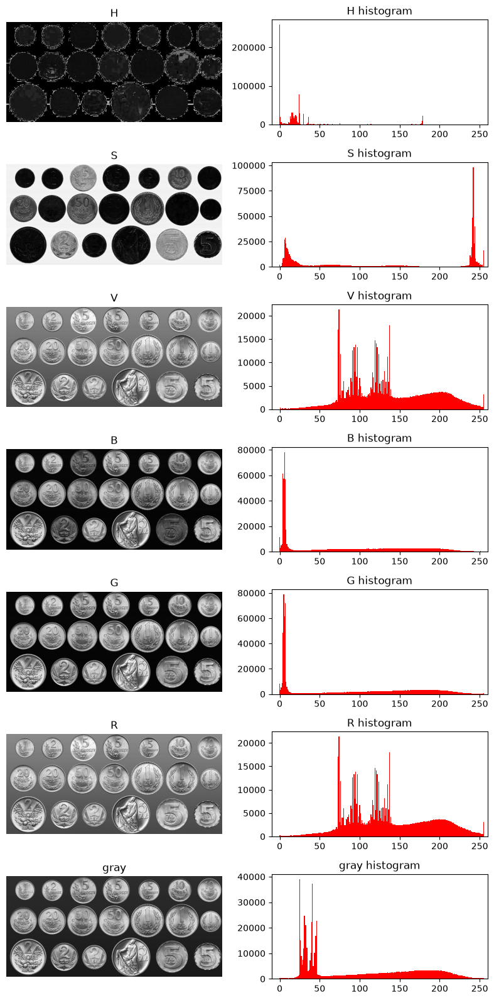

In [30]:
channels = {'H': H, 'S': S, 'V': V, 'B': monety_kolor[..., 0], 'G': monety_kolor[..., 1], 'R': monety_kolor[..., 2], 'gray': cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2GRAY)}
print(f"{'kanał':6s} {'T(Otsu)':>8s} {'eta':>6s}")
for name, channel in channels.items():
    T, eta = otsu_method(channel)
    print(f'{name:6s} {T:8.0f} {eta:6.2f}')

fig, ax = plt.subplots(7, 2, figsize=(8, 16))
for i, (name, channel) in enumerate(channels.items()):
    ax[i, 0].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[i, 0].set_title(name); ax[i, 0].axis('off')
    show_histogram(channel, axis=ax[i, 1], title=f'{name} histogram', color='red')
plt.tight_layout(); plt.show()

In [31]:
def hsv_preview(channel='S', T=100, inv=False, use_otsu=False):
    c = {'H': H, 'S': S, 'V': V, 'B': monety_kolor[..., 0], 'G': monety_kolor[..., 1], 'R': monety_kolor[..., 2], 'gray': cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2GRAY)}[channel]
    if use_otsu:
        T_, _ = cv2.threshold(c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        T_ = T
    _, bi_image = cv2.threshold(c, T_, 255, cv2.THRESH_BINARY_INV if inv else cv2.THRESH_BINARY)
    cut_out = cv2.bitwise_and(monety_kolor, monety_kolor, mask=bi_image)
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(c, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'kanał {channel}'); ax[0].axis('off')
    show_histogram(c, T_, ax[1], f'histogram {channel}')
    ax[2].imshow(bi_image, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'maska')
    ax[3].imshow(cut_out[..., ::-1]); ax[3].set_title('wycięte monety'); ax[3].axis('off')
    plt.show()

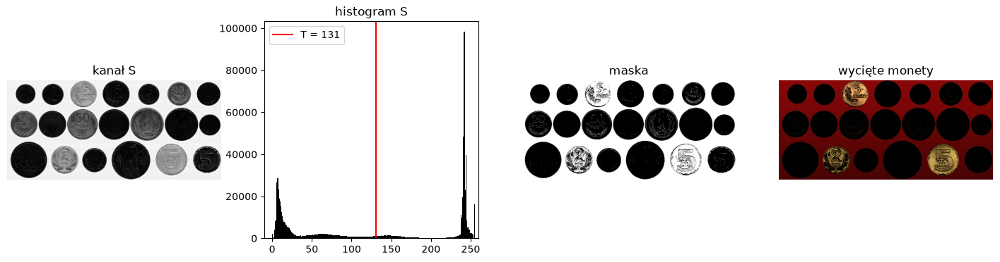

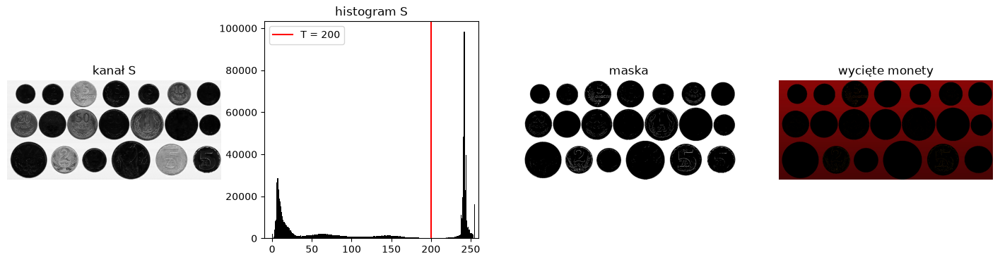

In [36]:
hsv_preview(channel='S', inv=False, use_otsu=True)
hsv_preview(channel='S', T=200, inv=False, use_otsu=False)

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

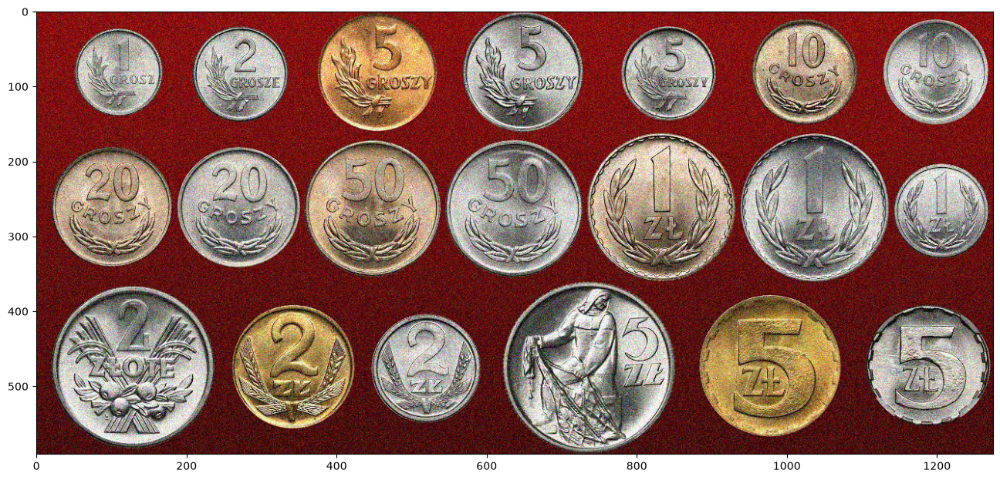

In [37]:
monety_kolor_szum = cv2.imread('Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

H: min/max = 0 179 | S: min/max = 0 255 | V: min/max = 0 255


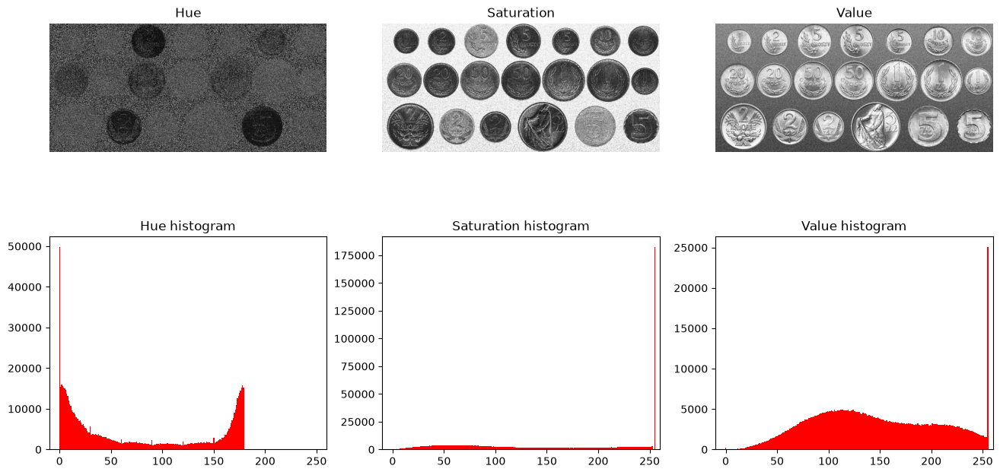

In [38]:
hsv_noise = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)
H_noise, S_noise, V_noise = cv2.split(hsv_noise)
print('H: min/max =', H_noise.min(), H_noise.max(), '| S: min/max =', S_noise.min(), S_noise.max(), '| V: min/max =', V_noise.min(), V_noise.max())

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (name, channel) in enumerate([('Hue', H_noise), ('Saturation', S_noise), ('Value', V_noise)]):
    ax[0, i].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[0, i].set_title(name); ax[0, i].axis('off')
    show_histogram(channel, axis=ax[1, i], title=f'{name} histogram', color='red')



kanał   T(Otsu)    eta
H            89   0.88
S           153   0.85
V           152   0.72
B            96   0.80
G            99   0.82
R           143   0.69
gray        113   0.82


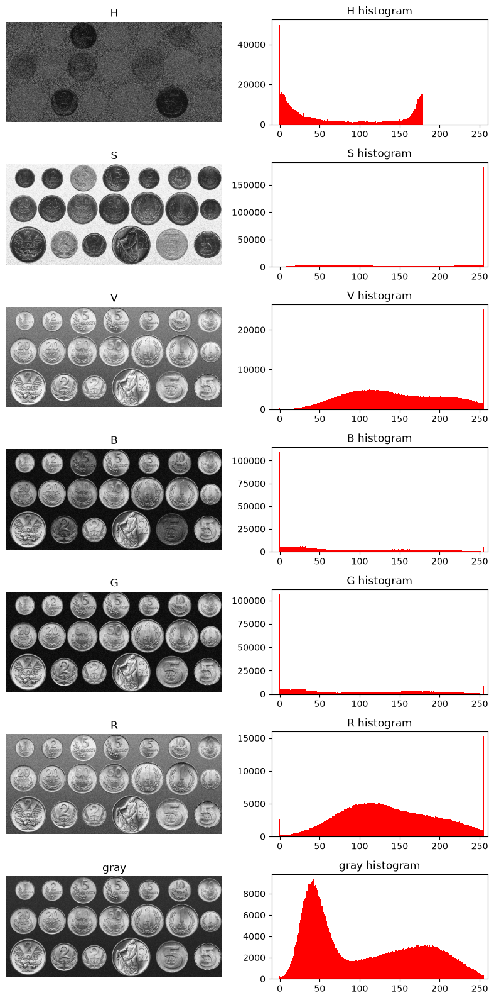

In [40]:
print(f"{'kanał':6s} {'T(Otsu)':>8s} {'eta':>6s}")
for name, channel in [('H', H_noise), ('S', S_noise), ('V', V_noise), ('B', monety_kolor_szum[..., 0]), ('G', monety_kolor_szum[..., 1]), ('R', monety_kolor_szum[..., 2]), ('gray', cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY))]:
    T, eta = otsu_method(channel)
    print(f'{name:6s} {T:8.0f} {eta:6.2f}')

fig, ax = plt.subplots(7, 2, figsize=(8, 16))
for i, (name, channel) in enumerate([('H', H_noise), ('S', S_noise), ('V', V_noise), ('B', monety_kolor_szum[..., 0]), ('G', monety_kolor_szum[..., 1]), ('R', monety_kolor_szum[..., 2]), ('gray', cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY))]):
    ax[i, 0].imshow(channel, cmap='gray', vmin=0, vmax=255); ax[i, 0].set_title(name); ax[i, 0].axis('off')
    show_histogram(channel, axis=ax[i, 1], title=f'{name} histogram', color='red')
plt.tight_layout(); plt.show()

In [41]:
def hsv_preview_noise(channel='S', T=100, inv=False, use_otsu=False):
    c = {'H': H_noise, 'S': S_noise, 'V': V_noise, 'B': monety_kolor_szum[..., 0], 'G': monety_kolor_szum[..., 1], 'R': monety_kolor_szum[..., 2], 'gray': cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2GRAY)}[channel]
    if use_otsu:
        T_, _ = cv2.threshold(c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        T_ = T
    _, bi_image = cv2.threshold(c, T_, 255, cv2.THRESH_BINARY_INV if inv else cv2.THRESH_BINARY)
    cut_out = cv2.bitwise_and(monety_kolor, monety_kolor, mask=bi_image)
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(c, cmap='gray', vmin=0, vmax=255); ax[0].set_title(f'kanał {channel}'); ax[0].axis('off')
    show_histogram(c, T_, ax[1], f'histogram {channel}')
    ax[2].imshow(bi_image, cmap='gray', vmin=0, vmax=255); ax[2].axis('off')
    ax[2].set_title(f'maska')
    ax[3].imshow(cut_out[..., ::-1]); ax[3].set_title('wycięte monety'); ax[3].axis('off')
    plt.show()


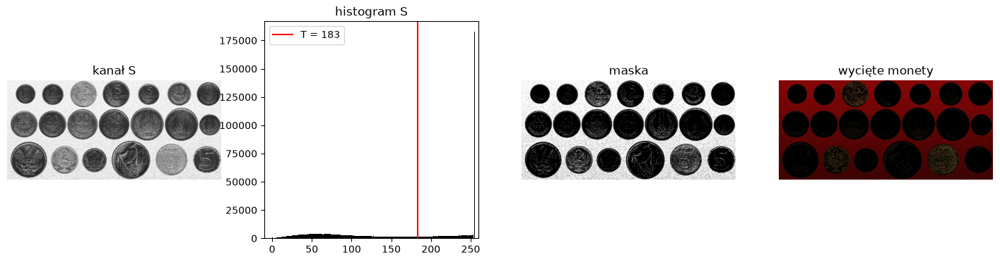

In [42]:
hsv_preview_noise(channel='S',T=183, inv=False, use_otsu=False)

In [43]:
def segment_S(bgr, method='mean', k=5, where='before'):
    if where == 'before':
        bgr = denoise_image(bgr, method, k)
    S_ = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[..., 1]
    if where == 'after':
        S_ = denoise_image(S_, method, k)
    T, bw = cv2.threshold(S_, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return S_, T, bw

ref_k = segment_S(monety_kolor, 'mean', 1)[2]
print(f"{'gdzie':6s} {'metoda':8s} {'k':>3s} {'IoU':>6s} {'eta(S)':>7s}")

for gdzie in ['before', 'after']:
    for m in ['mean', 'gaussian', 'median']:
        for k in [3, 5, 7, 9]:
            S_, T, bw = segment_S(monety_kolor_szum, m, k, gdzie)
            print(f'{gdzie:6s} {m:8s} {k:3d} 'f'{iou(bw, ref_k):6.3f} {otsu_method(S_)[1]:7.3f}')

gdzie  metoda     k    IoU  eta(S)
before mean       3  0.929   0.888
before mean       5  0.930   0.890
before mean       7  0.926   0.886
before mean       9  0.921   0.880
before gaussian   3  0.929   0.886
before gaussian   5  0.935   0.891
before gaussian   7  0.933   0.891
before gaussian   9  0.931   0.890
before median     3  0.910   0.877
before median     5  0.925   0.886
before median     7  0.925   0.888
before median     9  0.919   0.888
after  mean       3  0.880   0.867
after  mean       5  0.874   0.870
after  mean       7  0.871   0.868
after  mean       9  0.868   0.864
after  gaussian   3  0.886   0.868
after  gaussian   5  0.882   0.870
after  gaussian   7  0.877   0.871
after  gaussian   9  0.876   0.871
after  median     3  0.874   0.887
after  median     5  0.864   0.897
after  median     7  0.859   0.900
after  median     9  0.855   0.900


In [44]:
def preview_pipeline(method='mean', k=5, where='before'):
    S_, T, bw = segment_S(monety_kolor_szum, method, k, where)
    crop = cv2.bitwise_and(
        monety_kolor_szum,
        monety_kolor_szum,
        mask=bw
    )
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(S_, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title('S after denoising')
    ax[0].axis('off')

    show_histogram(S_, T, ax[1], 'S histogram')

    ax[2].imshow(bw, cmap='gray')
    ax[2].axis('off')
    ax[2].set_title(f'IoU={iou(bw, ref_k):.3f}')

    ax[3].imshow(crop[..., ::-1])
    ax[3].axis('off')

    plt.show()


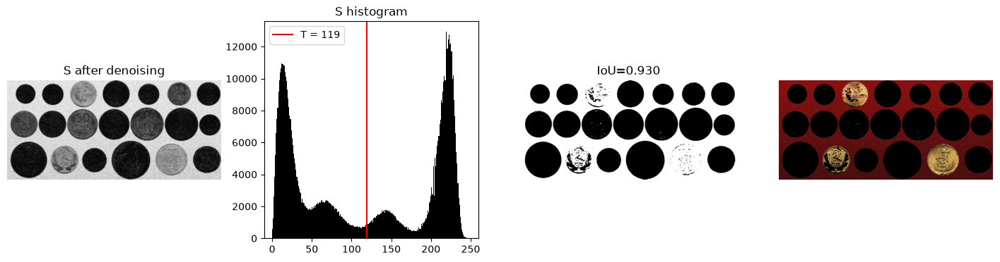

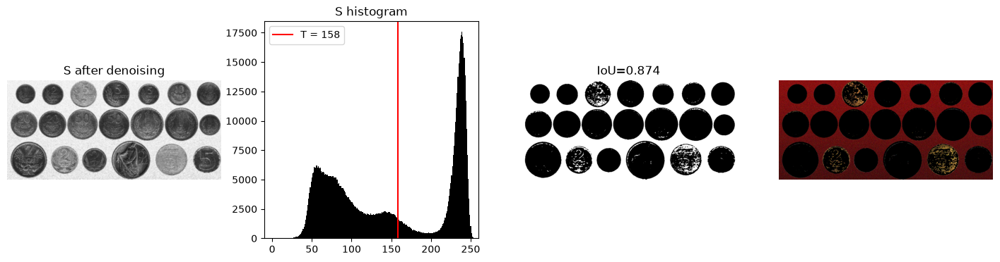

In [45]:
preview_pipeline(method='mean', k=5, where='before')
preview_pipeline(method='mean', k=5, where='after')

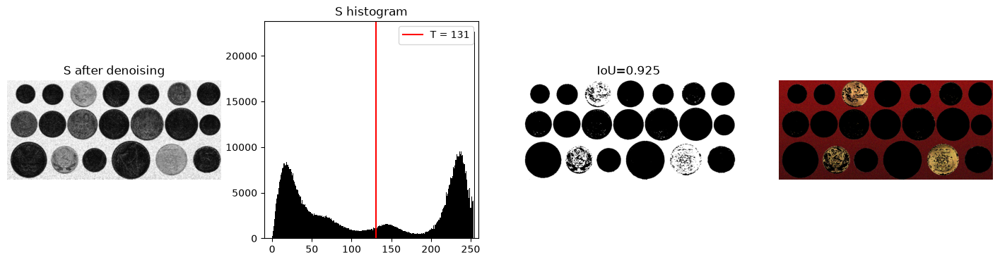

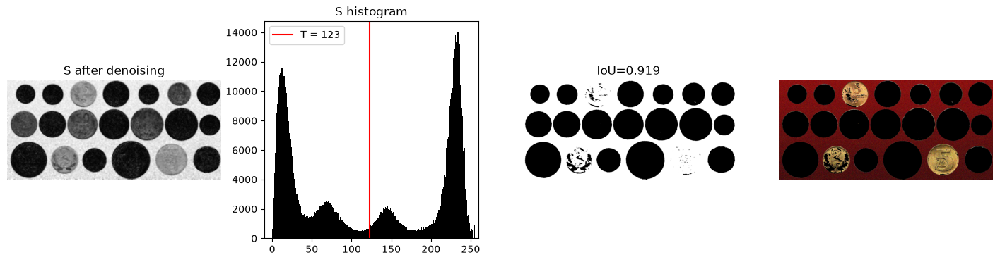

In [46]:
preview_pipeline(method='median', k=5, where='before')
preview_pipeline(method='median', k=9, where='before')

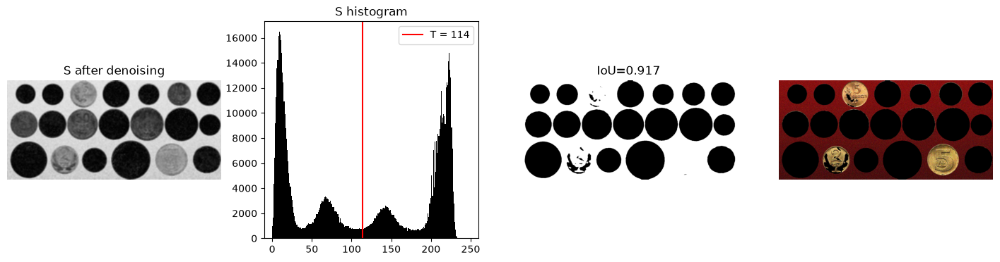

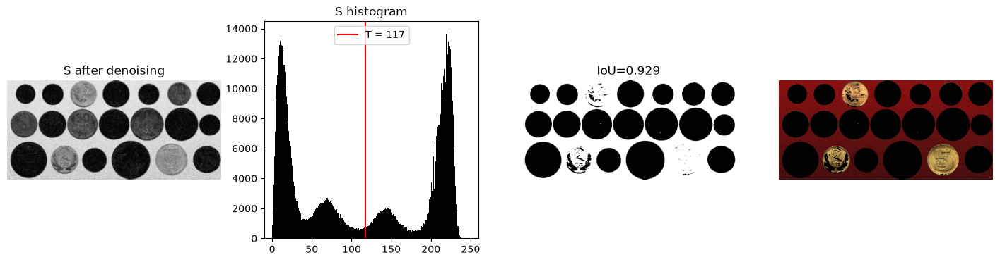

In [47]:
preview_pipeline(method='mean', k=11, where='before')
preview_pipeline(method='gaussian', k=11, where='before')


##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

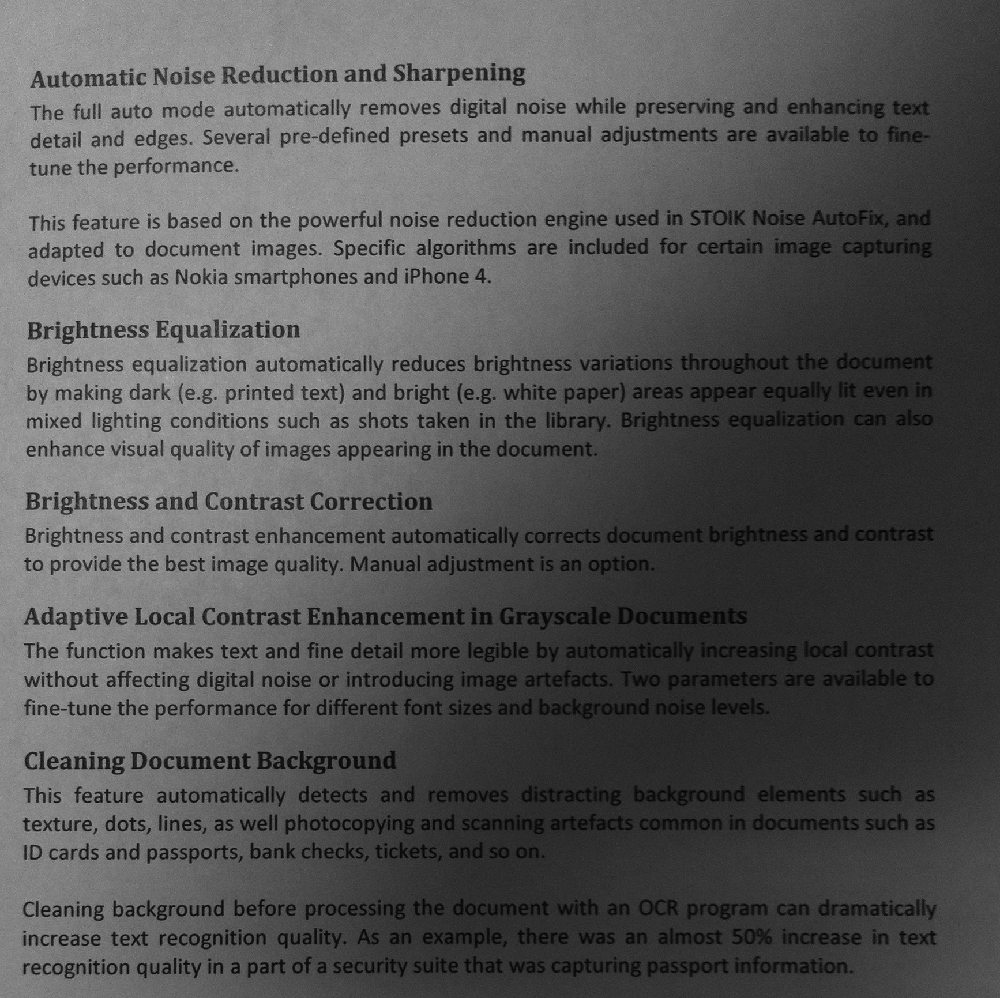

In [48]:
tekst = cv2.imread('Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

Rozwiązanie:

In [67]:
tekst.shape

(1731, 1734, 3)

In [82]:
import time
def otsu_local(image, window_size, step):
    assert 1 <= step <= window_size, 'Must have 1 <= step <= window_size'
    height, width = image.shape
    votes = np.zeros((height, width), dtype=np.uint32)
    counts = np.zeros((height, width), dtype=np.uint32)

    for y in range(0, height, step):
        for x in range(0, width, step):
            y_end = min(y + window_size, height)
            x_end = min(x + window_size, width)

            window = image[y:y_end, x:x_end]

            threshold, _ = cv2.threshold(
                window, 0, 255,
                cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )

            local_binary = (window > threshold).astype(np.uint32)

            votes[y:y_end, x:x_end] += local_binary
            counts[y:y_end, x:x_end] += 1

    binary = np.where(
        votes * 2 >= counts, 255, 0
    ).astype(np.uint8)

    return binary

def otsu_local(image, window_size, step, contrast=10):
    assert 1 <= step <= window_size, 'Must have 1 <= step <= window_size'
    height, width = image.shape
    votes = np.zeros((height, width), dtype=np.uint32)
    counts = np.zeros((height, width), dtype=np.uint32)

    for y in range(0, height, step):
        for x in range(0, width, step):
            y_end = min(y + window_size, height)
            x_end = min(x + window_size, width)

            window = image[y:y_end, x:x_end]

            p10, p90 = np.percentile(window, [10, 90])
            contr = p90 - p10
            if contr < contrast:
                local_binary = np.ones(window.shape, dtype=np.uint32)
            else:
                threshold, _ = cv2.threshold(
                    window, 0, 255,
                    cv2.THRESH_BINARY + cv2.THRESH_OTSU
                )
                local_binary = (window > threshold).astype(np.uint32)

            votes[y:y_end, x:x_end] += local_binary
            counts[y:y_end, x:x_end] += 1

    binary = np.where(
        votes * 2 >= counts, 255, 0
    ).astype(np.uint8)

    return binary

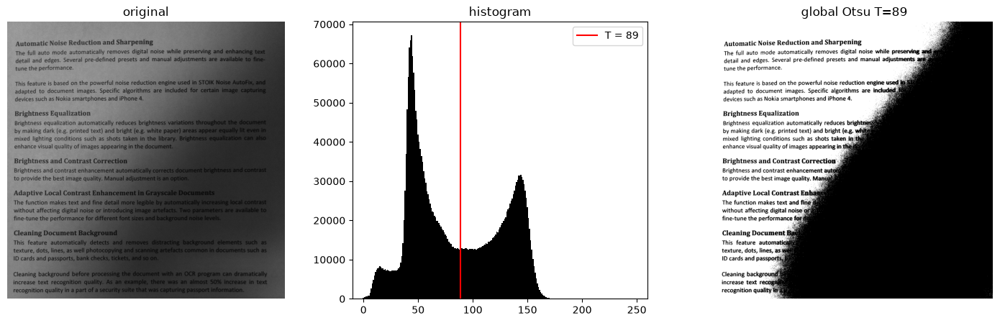

In [50]:
tekst_szary = cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY)

T_gt, bw_gt = cv2.threshold(tekst_szary, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].imshow(tekst_szary, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('original')
ax[0].axis('off')

show_histogram(
    tekst_szary, T_gt, ax[1],
    'histogram'
)

ax[2].imshow(bw_gt, cmap='gray')
ax[2].set_title(f'global Otsu T={T_gt:.0f}')
ax[2].axis('off')

plt.show()

Test rozmiaru okna:

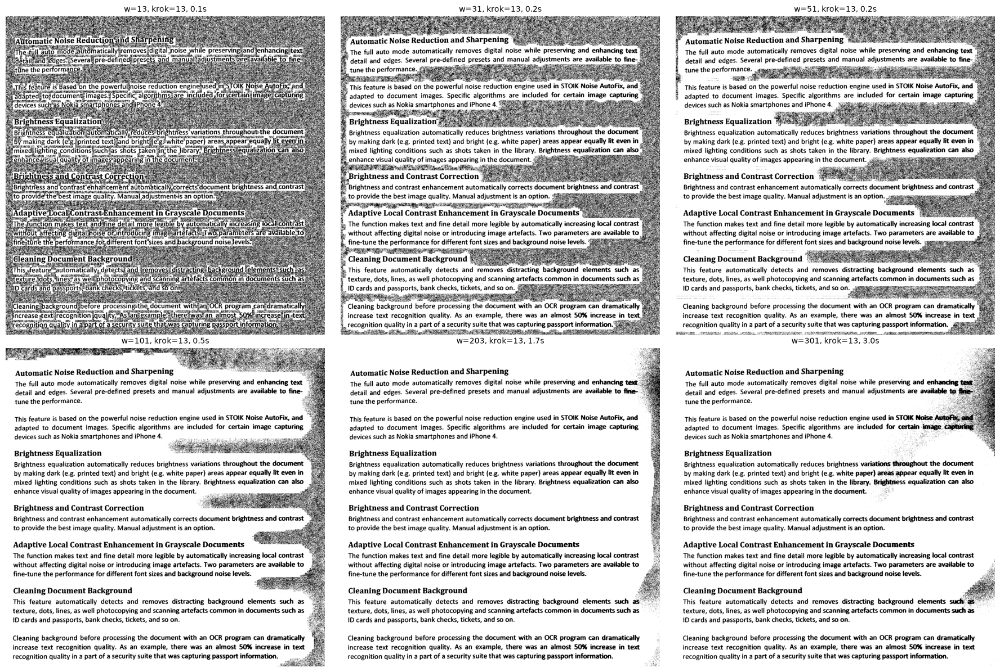

In [ ]:
images, titles = [], []

for w in [13, 31, 51, 101, 203, 301]:

    t0 = time.perf_counter()
    images.append(otsu_local(tekst_szary, w, 13))
    titles.append(
        f'w={w}, krok={13}, '
        f'{time.perf_counter() - t0:.1f}s'
    )

show_images(images, titles, columns=3, size=6)

To samo, ale z progiem do pozbywania sie szumu:

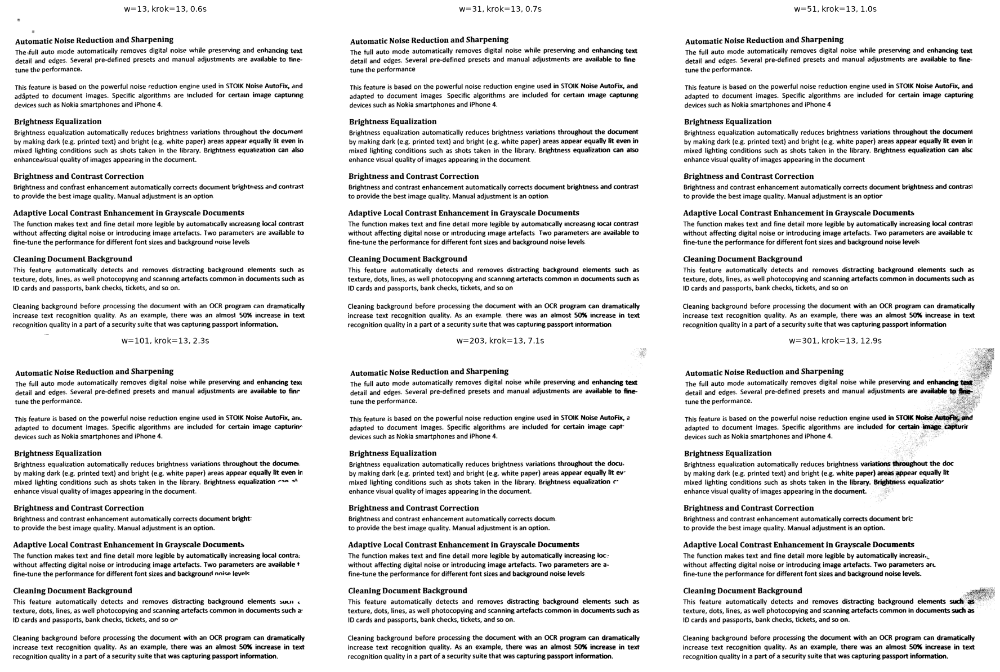

In [76]:
images, titles = [], []

for w in [13, 31, 51, 101, 203, 301]:

    t0 = time.perf_counter()
    images.append(otsu_local(tekst_szary, w, 13, 20))
    titles.append(
        f'w={w}, krok={13}, '
        f'{time.perf_counter() - t0:.1f}s'
    )

show_images(images, titles, columns=3, size=6)

Test rozmiaru kroku:

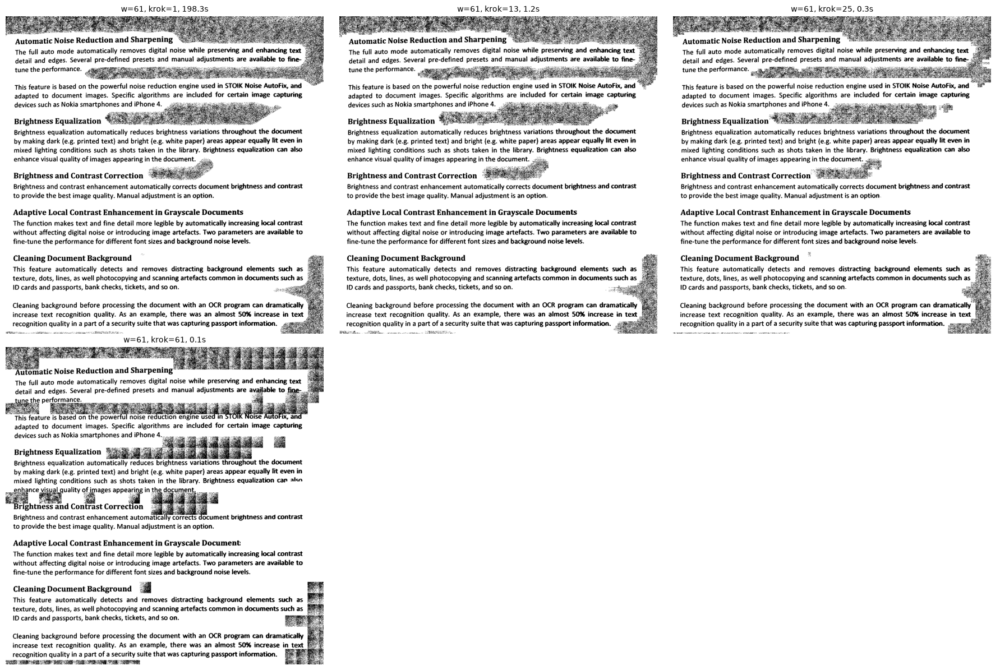

In [83]:

images, titles = [], []

for step in [1, 13, 25, 61]:

    t0 = time.perf_counter()
    images.append(otsu_local(tekst_szary, 61, step))

    titles.append(
        f'w=61, krok={step}, {time.perf_counter() - t0:.1f}s'
    )

show_images(images, titles, columns=3, size=6)

To samo ale z kontrastem do usuwania szumu:

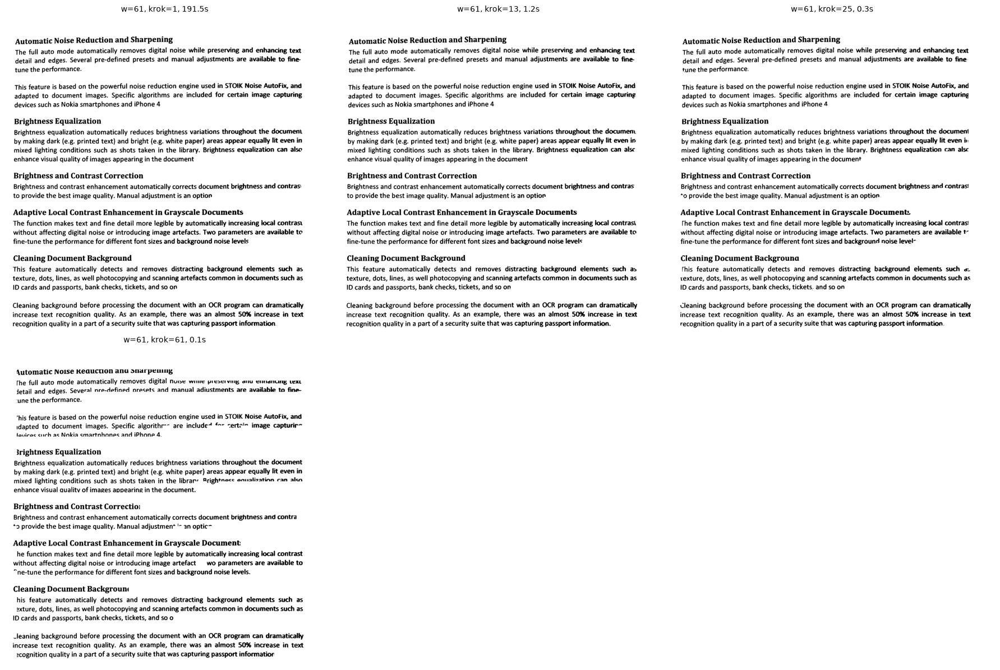

In [84]:

images, titles = [], []

for step in [1, 13, 25, 61]:

    t0 = time.perf_counter()
    images.append(otsu_local(tekst_szary, 61, step, 20))

    titles.append(
        f'w=61, krok={step}, {time.perf_counter() - t0:.1f}s'
    )

show_images(images, titles, columns=3, size=6)